In [1]:
%matplotlib widget
import sys
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import torch
import wandb
from tqdm import tqdm as _tqdm

tqdm = partial(_tqdm, file=sys.stdout, ncols=100, colour='blue')

torch.manual_seed(0)
np.random.seed(0)


In [17]:
from torch.utils.flop_counter import FlopCounterMode

from hexai.vvae import VVAE
from hexai.vvae import VVAEGeometric, VVAEGeometricConfig

# the real ones, so the notebook cannot drift from what train.py actually runs
from hexai.vvae.data import split_context_target
from hexai.vvae.train import log_novel_view, vvae_loss


def model_stats(target, show=True, context_frames=4):
    """Params, FLOPs, and the two numbers that gate the Pi: encoder-only cost (deployment
    never runs the decoder) and the level-0 activation that sets peak memory. Takes a config
    or a built model of either family, and always builds its own throwaway so the weights you
    passed are left where they are."""
    config = getattr(target, 'config', target)
    geometric = isinstance(config, VVAEGeometricConfig)
    h, w = config.render_hw if geometric else config.input_frame_hw

    if geometric:
        # on cpu, not meta: the lift drops out-of-box points, and nonzero has no meta rule
        model = VVAEGeometric(config)
        pose = torch.tensor([0.0, 0, 0, 1, 0, 0, 0])
        args = (torch.rand(1, config.in_channels, context_frames, h, w),
                pose.repeat(context_frames, 1).unsqueeze(0), pose.unsqueeze(0))
        act_mb = config.base_channels * np.prod(config.grid_resolution) * 4 / 1e6
    else:
        with torch.device('meta'):
            model = VVAE(config)
            args = (torch.randn(1, config.in_channels, config.num_frames, h, w),)
        act_mb = config.base_channels * config.num_frames * h * w * 4 / 1e6

    def gflop(module, inputs):
        with FlopCounterMode(display=False) as f: module(*inputs)
        return f.get_total_flops() / 1e9

    s = dict(
        params=sum(p.numel() for p in model.parameters()),
        enc_params=sum(p.numel() for p in model.encoder.parameters()),
        gflop=gflop(model, args),
        enc_gflop=gflop(model.encoder, args[:2] if geometric else args),
        act_mb=act_mb,
        levels=config.n_downsamples + 1, latent=config.latent_shape,
    )
    if show:
        print(f"params {s['params']/1e6:6.2f}M (enc {s['enc_params']/1e6:5.2f}M, {s['params']*4/1e6:4.0f} MB)  "
              f"GFLOP {s['gflop']:7.1f} (enc {s['enc_gflop']:6.1f})  "
              f"lvl0 act {s['act_mb']:4.0f} MB  levels {s['levels']}  latent {s['latent']}")
    return s

#### Load a dataset to test with

In [3]:
%%script /home/marcocassar/workspace/projects/ml/tartanairpy/.venv/bin/python
import os
from itertools import product
from pathlib import Path

os.environ["MPLBACKEND"] = "Agg"  # headless backend | error in tartanair

import tartanair as ta

data_root = Path("../../../../data/tartanground")
ta.init(str(data_root))  # adjust if your notebook's cwd differs from repo root

tartan_env, version = "House", "omni"
trajectories = ["P0000", "P0001", "P0002"]  # House's only 3 trajectories
modalities = ["image", "depth"]
camera_names = ["lcam_front", "lcam_bottom"]

# download_ground always overwrites on unzip, so disk check + skip if there
house_root = data_root / tartan_env / f"Data_{version}"
dirs = [house_root / t / f"{m}_{c}" for t, m, c in product(trajectories, modalities, camera_names)]

if all(d.is_dir() and any(d.iterdir()) for d in dirs):
    print("All requested data already present on disk -- skipping download.")
else:
    ta.download_ground(
        env=[tartan_env], version=[version], traj=[],
        modality=modalities, camera_name=camera_names, unzip=True,
    )

TartanAir toolbox initialized.
All requested data already present on disk -- skipping download.


In [4]:
%load_ext autoreload
%autoreload 3
from hexai.vvae import VVAEConfig

vvae_config = VVAEConfig(in_channels=4, input_frame_hw=(640,640), num_frames=6, downsample_scale=4,
                         kernel_size=3, groups=2)
vvae = VVAE(vvae_config)
print(f"Num Parameters: {sum(p.numel() for p in vvae.parameters()):,}")

Num Parameters: 9,504,332


In [5]:
from pathlib import Path

from hexai.vvae.data import (
    TartanGroundWindowDataset,
    find_trajectory_dirs,
    make_dataloader,
)

house_root = Path("../../../../data/tartanground/House/Data_omni")
dataset = TartanGroundWindowDataset(
    trajectory_paths=find_trajectory_dirs(house_root),
    num_frames=vvae_config.num_frames,  # keep in sync with the VVAE's config
    camera_names=("lcam_front", "lcam_bottom"),  # stacked front over bottom, they join

)
print(f"{len(dataset)} windows")

def train_test_split(dset: TartanGroundWindowDataset, batch_size=4):
    # subset it for the train and test
    train_dataset = dset.get_trajectory(dset.trajectory_paths[1:])
    test_dataset = dset.get_trajectory(dset.trajectory_paths[:1])

    return (make_dataloader(train_dataset, batch_size=batch_size, shuffle=True),
            make_dataloader(test_dataset, batch_size=batch_size, shuffle=True))


# test a batch
train_loader, test_loader = train_test_split(dataset)

batch = next(iter(train_loader))
print("batch shape:", tuple(batch.shape))

714 windows
batch shape: (4, 4, 6, 640, 640)


In [6]:
import io

from IPython.display import Image as IPImage
from PIL import Image


def _make_gif(panels, fps, path=None):
    """Panels laid out left to right, each [4, T, H, W]: rgb over colormapped depth.
    Returns the gif bytes, and writes them to path as well if you pass one."""
    depth_cmap = plt.colormaps['viridis']
    def panel(t):  # [4, T, H, W] -> [T, 2H, W, 3] uint8
        rgb = t[:3].permute(1, 2, 3, 0).numpy()
        depth = depth_cmap(t[3].numpy())[..., :3]
        return (np.concatenate([rgb, depth], axis=1) * 255).astype(np.uint8)

    frames = [Image.fromarray(f) for f in np.concatenate([panel(p) for p in panels], axis=2)]
    buf = io.BytesIO()
    frames[0].save(buf, format='GIF', save_all=True, append_images=frames[1:],
                   duration=1000 // fps, loop=0)
    if path: Path(path).write_bytes(buf.getvalue())
    return buf.getvalue()


@torch.no_grad()
def decode_latent(model, latent):
    """One [C, D, H, W] latent -> the [4, T, H, W] window it decodes to, in [0, 1]."""
    was_training = model.training
    model.eval()
    device = next(model.parameters()).device
    x_hat = model.decoder(latent.unsqueeze(0).to(device))[0].clamp(0, 1).cpu()
    if was_training: model.train()
    return x_hat


def log_reconstruction(model, latent, original, step=None, key='recon', fps=4, path=None):
    """[what went in | what that latent decodes back to], side by side."""
    data = _make_gif([original.cpu(), decode_latent(model, latent)], fps, path)
    if wandb.run is not None: wandb.log({key: wandb.Video(io.BytesIO(data), format='gif')}, step=step)
    return IPImage(data=data, format='gif')


def log_generated(model, step=None, key='generated', fps=4, path=None):
    """Decode a latent from the prior randn, the KL term pulls the posterior toward a standard
    normal, so N(0,1) is the distribution the decoder was trained to expect."""
    z = torch.randn(model.decoder.config.latent_shape)
    data = _make_gif([decode_latent(model, z)], fps, path)
    if wandb.run is not None: wandb.log({key: wandb.Video(io.BytesIO(data), format='gif')}, step=step)
    return IPImage(data=data, format='gif')

In [ ]:
out = vvae(batch)
log_reconstruction(vvae, out.z_hat[0], batch[0])
log_generated(vvae)

### Training


In [10]:
project = "vvae"

def train_test(model, train_loader, test_loader, name=None, epochs=20, lr=0.001, beta=1.0, device='cuda', n_epochs=5):
    config = {
        "epochs": epochs,
        "batch_size": train_loader.batch_size,
        "learning_rate": lr,
        "beta": beta,
        "model": model.__class__.__name__,
        "optimizer": "Adam"
    }

    with wandb.init(project=project, name=name, config=config) as run:
        model = model.to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

        sample = next(iter(test_loader))[0]  # same window every time so the gifs are comparable
        global_step = 1

        for epoch in range(epochs):
            model.train()
            pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}')

            for data in pbar:
                data = data.to(device)
                optimizer.zero_grad()

                t_loss, t_recon, t_kl = vvae_loss(model(data), data, beta)
                t_loss.backward()
                optimizer.step()

                pbar.set_postfix(loss=f'{t_loss.item():.3g}', recon=f'{t_recon.item():.3g}', kl=f'{t_kl.item():.3g}')
                run.log({"train/loss": t_loss.item(), "train/recon": t_recon.item(), "train/kl": t_kl.item()}, step=global_step)
                global_step += 1

            model.eval()
            totals, n = [0.0, 0.0, 0.0], 0
            with torch.no_grad():
                for data in tqdm(test_loader, desc='val', leave=False):
                    data = data.to(device)
                    totals = [t + l.item() * len(data) for t, l in zip(totals, vvae_loss(model(data), data, beta))]
                    n += len(data)

            v_loss, v_recon, v_kl = [t / n for t in totals]
            print(f'epoch {epoch+1}: val loss {v_loss:.4g} (recon {v_recon:.4g}, kl {v_kl:.4g})')
            run.log({"val/loss": v_loss, "val/recon": v_recon, "val/kl": v_kl}, step=global_step)
            torch.save(model.state_dict(), f'{run.name}.pt')

            if epoch % n_epochs == 0:
                with torch.no_grad():
                    mu, _ = model.encoder(sample.unsqueeze(0).to(device))
                log_reconstruction(model, mu[0], sample, step=global_step)
                log_generated(model, step=global_step)

    return model

In [ ]:
train_test(vvae, train_loader, test_loader)

wandb: Currently logged in as: marcocassar (marcocassar-belmont-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch 1/20: 100%|█████| 149/149 [28:37<00:00, 11.53s/it, kl=2.45e+03, loss=1.37e+05, recon=1.34e+05]
epoch 1: val loss 2.466e+05 (recon 2.443e+05, kl 2245)                                              2.30s/it]
Epoch 2/20: 100%|█████| 149/149 [23:52<00:00,  9.62s/it, kl=1.57e+03, loss=1.75e+05, recon=1.74e+05]
epoch 2: val loss 1.647e+05 (recon 1.623e+05, kl 2366)                                              1.69s/it]
Epoch 3/20: 100%|█████| 149/149 [25:06<00:00, 10.11s/it, kl=3.55e+03, loss=1.67e+05, recon=1.64e+05]
epoch 3: val loss 1.539e+05 (recon 1.505e+05, kl 3391)                                              2.27s/it]
Epoch 4/20: 100%|█████| 149/149 [28:09<00:00, 11.34s/it, kl=2.52e+03, loss=9.59e+04, recon=9.34e+04]
epoch 4: val loss 1.388e+05 (recon 1.361e+05, kl 2675)                                              2.29s/it]
Epoch 5/20: 100%|██████| 149/149 [28:12<00:00, 11.36s/it, kl=3.21e+03, loss=9.6e+04, recon=9.28e+04]
epoch 5: val loss 1.528e+05 (recon 1.496e+05, kl 3252) 

train/kl,█▃▂▃▂▁▂▂▃▂▁▂▂▂▃▅▂▃▂▂▁▃▂▂▂▁▂▂▂▂▃▁▁▁▂▂▂▂▁▃
train/loss,██▅▄▃▄▃▃▂▂▃▃▂▄▄▃▁▄▃▁▃▃▃▂▂▄▃▁▁▁▁▂▂▂▂▁▂▂▂▃
train/recon,▇▅█▄█▃▃▄▃▃▂▂▃▃▃▁▃▄▂▂▂▃▁▁▂▁▁▂▃▂▃▂▂▁▂▂▃▃▂▂
val/kl,▁▂█▄▇█▄▆▆▄▇▇▄▄▃▅▄▃▄▄
val/loss,█▄▄▃▄▃▃▄▃▂▂▂▂▂▃▃▁▁▁▂
val/recon,█▄▄▃▄▃▃▄▃▂▂▂▂▂▃▃▁▁▁▂
train/kl,2542.37329
train/loss,52169.66016
train/recon,49627.28906
val/kl,2659.6232
val/loss,109316.39579


VVAE(
  (encoder): VVAEEncoder(
    (conv): Conv3d(4, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (norm): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (levels): ModuleList(
      (0): ModuleList(
        (0-1): 2 x VVAEBlock(
          (final_act): ReLU()
          (levels): ModuleList(
            (0): Sequential(
              (0): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), groups=2, bias=False)
              (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
              (2): ReLU()
              (3): Dropout3d(p=0.0, inplace=False)
            )
            (1): Sequential(
              (0): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), groups=2, bias=False)
              (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
              (2): ReLU()
            )
          )
        )
      )
      (1): ModuleList(
        (0-1): 2 x VVAEBlock(
          (final_ac

In [11]:
resized_dataset = TartanGroundWindowDataset(
    trajectory_paths=find_trajectory_dirs(house_root),
    num_frames=vvae_config.num_frames,  # keep in sync with the VVAE's config
    camera_names=("lcam_front", "lcam_bottom"),  # stacked front over bottom, they join
    image_hw=(320,320)
)
print(f"{len(resized_dataset)} windows")

# subset it for the train and test
resized_train_loader, resized_test_loader= train_test_split(resized_dataset)

714 windows


In [18]:
large_kernal_vvae_config = VVAEConfig(in_channels=4, input_frame_hw=(320,320), num_frames=6, downsample_scale=4,
                         kernel_size=7, groups=2)
lk_vvae = VVAE(large_kernal_vvae_config)
model_stats(large_kernal_vvae_config)

params  29.62M (enc 14.81M,  118 MB)  GFLOP  2377.1 (enc 1187.1)  lvl0 act   79 MB  levels 3  latent (4, 7, 7, 7)


{'params': 29617100,
 'enc_params': 14808776,
 'gflop': 2377.109738496,
 'enc_gflop': 1187.080484864,
 'act_mb': 78.6432,
 'levels': 3,
 'latent': (4, 7, 7, 7)}

In [13]:
train_test(lk_vvae, train_loader=resized_train_loader, test_loader=resized_test_loader, epochs=1, )

wandb: Currently logged in as: marcocassar (marcocassar-belmont-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Epoch 1/1: 100%|██████| 149/149 [37:57<00:00, 15.28s/it, kl=4.99e+03, loss=5.12e+04, recon=4.62e+04]
epoch 1: val loss 8.361e+04 (recon 7.812e+04, kl 5498)                                              2.09s/it]


train/kl,▁▅▆▇▇▇████▇▆▆▆▇▆▆▆▅▆▆▅▅▅▅▄▄▅▅▄▄▄▃▃▃▃▃▃▂▁
train/loss,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/recon,▁█▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
val/kl,▁
val/loss,▁
val/recon,▁
train/kl,4992.03223
train/loss,51221.67188
train/recon,46229.64062
val/kl,5498.04558
val/loss,83613.86123


VVAE(
  (encoder): VVAEEncoder(
    (conv): Conv3d(4, 32, kernel_size=(7, 7, 7), stride=(1, 1, 1), padding=(3, 3, 3), bias=False)
    (norm): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (levels): ModuleList(
      (0): ModuleList(
        (0-1): 2 x VVAEBlock(
          (final_act): ReLU()
          (levels): ModuleList(
            (0): Sequential(
              (0): Conv3d(32, 32, kernel_size=(7, 7, 7), stride=(1, 1, 1), padding=(3, 3, 3), groups=4, bias=False)
              (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
              (2): ReLU()
              (3): Dropout3d(p=0.0, inplace=False)
            )
            (1): Sequential(
              (0): Conv3d(32, 32, kernel_size=(7, 7, 7), stride=(1, 1, 1), padding=(3, 3, 3), groups=4, bias=False)
              (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
              (2): ReLU()
            )
          )
        )
      )
      (1): ModuleList(
        (0-1): 2 x VVAEBlock(
          (final_ac

In [ ]:
# experiment with later
@torch.no_grad()
def warp_time(t, dt=None, s=.5):
    """Parametric Time Warping: s = slope in the middle.
        s=1 is linear time, s < 1 goes slower near the middle, s>1 goes slower near the ends
        s = 1.5 gets very close to the "cosine schedule", i.e. (1-cos(pi*t))/2, i.e. sin^2(pi/2*x)"""
    if s < 0 or s > 1.5: raise ValueError(f"s={s} is out of bounds.")
    tw = 4 * (1 - s) * t ** 3 + 6 * (s - 1) * t ** 2 + (3 - 2 * s) * t
    if dt:  # warped time-step requested; use derivative
        return tw, dt * 12 * (1 - s) * t ** 2 + 12 * (s - 1) * t + (3 - 2 * s)
    return tw

overfitting one batch: 100%|██████████████████████████████████████| 150/150 [00:12<00:00, 12.12it/s]
loss 161.7  recon 147.0  kl 14.7


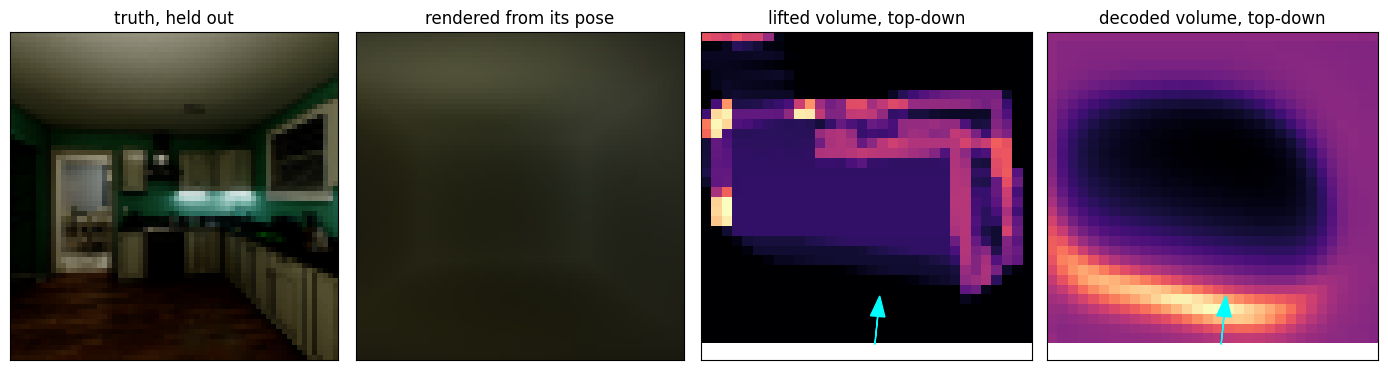

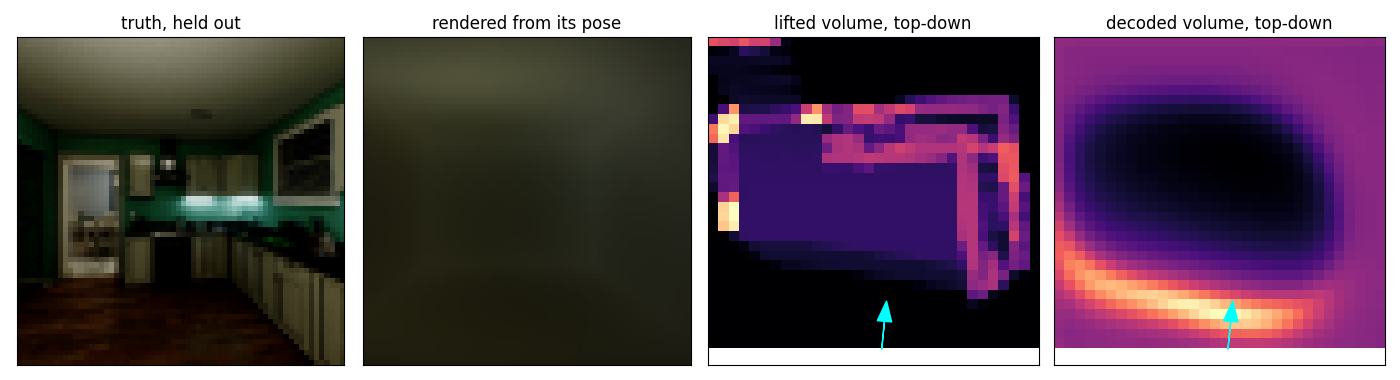

In [22]:
# smoke test: overfit one batch, then look. loss falling is not enough -- a saturated density field
# renders flat grey and looks the same as undertrained, which is what the two volumes catch

geo_dataset = TartanGroundWindowDataset(
    trajectory_paths=find_trajectory_dirs(house_root),
    num_frames=5, image_hw=(64, 64), include_pose=True,
)
geo_train, geo_test = train_test_split(geo_dataset, batch_size=4)

geo = VVAEGeometric(VVAEGeometricConfig(render_hw=(64, 64))).to('cuda')
assert geo_dataset.camera == geo.camera, (geo_dataset.camera, geo.camera)

batch = next(iter(geo_train))
context, context_poses, target, query = split_context_target(*batch, target=1)
context, context_poses, query, target = (x.to('cuda') for x in (context, context_poses, query, target))

optimizer = torch.optim.Adam(geo.parameters(), lr=1e-3)
for _ in tqdm(range(150), desc='overfitting one batch'):
    optimizer.zero_grad()
    loss, recon, kl = vvae_loss(geo(context, context_poses, query), target)
    loss.backward(); optimizer.step()
print(f"loss {loss.item():.1f}  recon {recon.item():.1f}  kl {kl.item():.1f}")

log_novel_view(geo, batch, target=1)

In [ ]:
# training runs as a module now:
#   uv run python -m hexai.vvae.train --jitter=1 --lr=0.003
# sweeps are defined in sweep.json alongside it

In [18]:
model_stats(geo)

params   1.12M (enc  0.56M,    4 MB)  GFLOP    16.8 (enc    8.3)  lvl0 act    3 MB  levels 2  latent (4, 7, 7, 7)


{'params': 1119372,
 'enc_params': 559816,
 'gflop': 16.761702912,
 'enc_gflop': 8.337120256,
 'act_mb': np.float64(3.145728),
 'levels': 2,
 'latent': (4, 7, 7, 7)}

In [32]:
test_geo = VVAEGeometricConfig(render_hw=(64, 64), n_downsamples=2, 
                    downsample_scale=2, kernel_size=3, 
                    base_channels=32, groups=2)
#  base_channels: int = 32
#   kernel_size: int = 3
#   n_downsamples
#   downsample_scale: int = 2
#   use_skips: bool = True
#   norm: Callable[[int], nn.Module] | None = partial(nn.GroupNorm, 8)
#   dropout: float = 0.0
#   groups: int = 1
#   blocks_per_level: int = 2
#   levels_per_block: int = 2
model_stats(test_geo)

params   2.36M (enc  1.18M,    9 MB)  GFLOP    10.0 (enc    4.9)  lvl0 act    3 MB  levels 3  latent (4, 8, 6, 8)


{'params': 2355148,
 'enc_params': 1177800,
 'gflop': 10.024206336,
 'enc_gflop': 4.946460672,
 'act_mb': np.float64(3.145728),
 'levels': 3,
 'latent': (4, 8, 6, 8)}

VVAEGeometric(
  (encoder): VVAEGeometricEncoder(
    (conv): Conv3d(4, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (norm): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (levels): ModuleList(
      (0): Sequential(
        (0): VVAEBlock(
          (final_act): ReLU()
          (levels): ModuleList(
            (0): Sequential(
              (0): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), groups=2, bias=False)
              (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
              (2): ReLU()
              (3): Dropout3d(p=0.0, inplace=False)
            )
            (1): Sequential(
              (0): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), groups=2, bias=False)
              (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
              (2): ReLU()
            )
          )
        )
        (1): VVAEBlock(
          (final_act): ReLU()
          (lev